In [6]:
!pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]




[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Using device: cpu


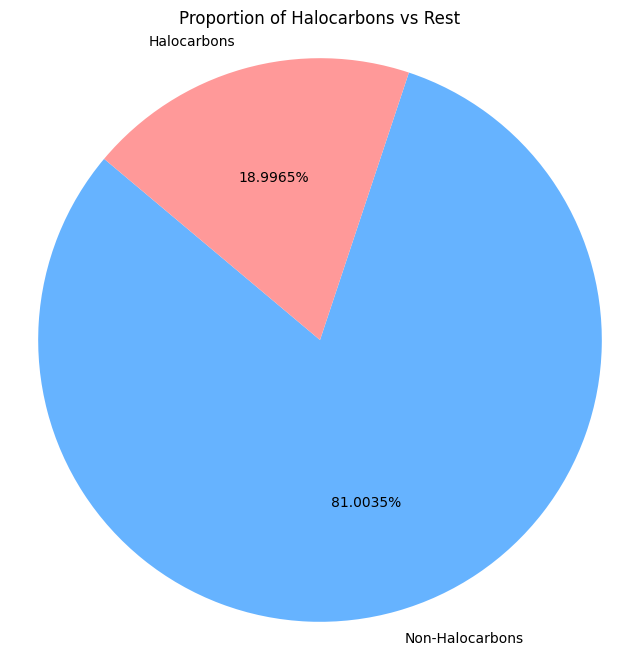

[19:06:54] WARNING: not removing hydrogen atom without neighbors


Number of molecules with NumAtoms <= 30: 3728


[19:06:56] WARNING: not removing hydrogen atom without neighbors


{'F': 350, 'Cl': 472, 'Br': 249, 'O': 1994, 'N': 779}
  Found extra experimental file: Critical_Properties_dataset_exp.xlsx


In [ ]:
# ======================================================================================
# CELL 1: Installs (run these in separate Kaggle cells with !)
# ======================================================================================
!pip install RDKit
!pip install pubchempy
!pip install torch_geometric
!pip install openpyxl

# ======================================================================================
# CELL 2: Imports
# ======================================================================================
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from rdkit import Chem
from rdkit.Chem import Descriptors, MACCSkeys, AllChem, Descriptors3D
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from torch.utils.data import Dataset
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import MessagePassing, global_add_pool
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ======================================================================================
# CELL 3: Data Loading & Halocarbon Analysis (unchanged)
# ======================================================================================
df = pd.read_csv('critprop_data_only_smiles_mean_value_expt.csv')

def is_halocarbon(smiles):
    if not isinstance(smiles, str):
        return False
    if 'F' in smiles or 'Cl' in smiles or 'Br' in smiles or 'I' in smiles:
        return True
    return False

df['is_halocarbon'] = df['smiles'].apply(is_halocarbon)

counts = df['is_halocarbon'].value_counts()
halocarbons_count = counts.get(True, 0)
non_halocarbons_count = counts.get(False, 0)

sizes = [non_halocarbons_count, halocarbons_count]
labels = ['Non-Halocarbons', 'Halocarbons']

plt.figure(figsize=(8, 8))
plt.pie(sizes, labels=labels, autopct='%1.4f%%', startangle=140, colors=['#66b3ff', '#ff9999'])
plt.title('Proportion of Halocarbons vs Rest')
plt.axis('equal')
plt.savefig('halocarbons_pie_chart.png')
plt.show()

# ======================================================================================
# CELL 4: Data Filtering Functions (unchanged)
# ======================================================================================
def count_atoms(smiles):
    if pd.isna(smiles):
        return np.nan
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.nan
    mol = Chem.AddHs(mol)
    return mol.GetNumAtoms()

def count_molecules_with_atom(df, smiles_col="smiles", atoms=("F","Cl","Br","O","N")):
    counts = {atom: 0 for atom in atoms}
    for smiles in df[smiles_col]:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            continue
        present = {atom.GetSymbol() for atom in mol.GetAtoms()}
        for atom in atoms:
            if atom in present:
                counts[atom] += 1
    return counts

def joback_predictions(smiles):
    if smiles is None:
        return None
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    mol_with_hs = Chem.AddHs(mol)
    num_atoms = mol_with_hs.GetNumAtoms()

    joback_groups = {
        "[CH3;X4;!R]": (23.58, 0.0141, 0.0012),
        "[CH2;X4;!R]": (22.88, 0.0189, 0.0000),
        "[CH;X4;!R]":  (21.74, 0.0164, 0.0020),
        "[C;X4;!R]":   (18.25, 0.0067, 0.0043),
        "[CH2X3;!R;$([CH2]=*)]": (18.18, 0.0113, -0.0028),
        "[CHX3;!R;$([CH]=*)]": (24.96, 0.0129, -0.0006),
        "[CX3;!R;$([CX3]=*);!$([CX3]=O)]": (24.14, 0.0117, 0.0011),
        "[CH2;X4;R]":  (27.15, 0.0100, 0.0025),
        "[CH;X4;R]":   (21.78, 0.0122, 0.0039),
        "[C;X4;R]":    (21.32, 0.0042, 0.0061),
        "[OH;X2;!R]":  (92.88, 0.0741, 0.0112),
        "[O;X2;!R]":   (22.42, 0.0168, 0.0015),
        "[C;X3;!R]=O": (76.75, 0.0400, 0.0085),
        "[CX3;!R](=[OX1])[OX2H1]": (155.5, 0.0791, 0.0077),
        "[F]":  (-0.03, 0.0111, -0.0002),
        "[Cl]": (38.13, 0.0105, 0.0040),
        "[Br]": (66.86, 0.0133, 0.0057),
        "[I]":  (93.84, 0.0230, 0.0072),
        "[NH2;X3;!R]": (73.23, 0.0243, 0.0109),
    }

    sum_dtb, sum_dtc, sum_dpc = 0.0, 0.0, 0.0
    used_atoms = set()

    for smarts, inc in joback_groups.items():
        patt = Chem.MolFromSmarts(smarts)
        if patt is None:
            continue
        matches = mol.GetSubstructMatches(patt)
        for match in matches:
            if match[0] in used_atoms:
                continue
            sum_dtb += inc[0]
            sum_dtc += inc[1]
            sum_dpc += inc[2]
            used_atoms.update(match)

    try:
        Tb = 198 + sum_dtb
        Tc = Tb / (0.584 + 0.965*sum_dtc - sum_dtc**2)
        Pc_bar = (0.113 + 0.0032*num_atoms - sum_dpc)**(-2)
        return {
            "SMILES": smiles, "Tb (K)": Tb, "Tc (K)": Tc,
            "Pc (bar)": Pc_bar, "Pc (MPa)": Pc_bar / 10
        }
    except:
        return None

def iupac_to_smiles(name):
    if pd.isna(name) or not isinstance(name, str):
        return None
    try:
        import pubchempy as pcp
        results = pcp.get_compounds(name, namespace='name')
        if not results:
            return None
        smiles = results[0].connectivity_smiles
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            return None
        return Chem.MolToSmiles(mol, canonical=True)
    except Exception:
        return None

def fill_missing_Tc_with_joback(df, smiles_col="smiles", tc_col="Tc (K)"):
    df = df.copy()
    missing_indices = df[df[tc_col].isna()].index
    for i in missing_indices:
        smiles = df.loc[i, smiles_col]
        if pd.isna(smiles):
            continue
        try:
            result = joback_predictions(smiles)
            if result is None:
                continue
            df.loc[i, tc_col] = result["Tc (K)"]
        except Exception as e:
            print(f"Failed for index {i}, SMILES {smiles}: {e}")
    return df

def element_bond_tc_prediction(smiles, tb_experimental):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None or tb_experimental is None:
        return np.nan
    mol = Chem.AddHs(mol)
    a_const = 1.5530
    b_const = 18.999

    element_delta = {
        "C": -0.0003, "H": -0.0016, "O": -0.0472, "N": -0.0533,
        "S": 0.0179, "F": -0.0478, "Cl": -0.0380, "Br": 0.0071,
        "I": 0.0091, "Si": 0.0224
    }
    bond_delta = {
        (("C","C"), Chem.rdchem.BondType.SINGLE, False): -0.0168,
        (("C","C"), Chem.rdchem.BondType.DOUBLE, False): -0.0080,
        (("C","C"), Chem.rdchem.BondType.TRIPLE, False): -0.0079,
        (("C","O"), Chem.rdchem.BondType.SINGLE, False): 0.0059,
        (("C","O"), Chem.rdchem.BondType.DOUBLE, False): 0.0200,
        (("O","O"), Chem.rdchem.BondType.SINGLE, False): 0.0000,
        (("O","H"), Chem.rdchem.BondType.SINGLE, False): -0.0114,
        (("C","H"), Chem.rdchem.BondType.SINGLE, False): -0.0001,
        (("C","F"), Chem.rdchem.BondType.SINGLE, False): 0.0285,
        (("C","Cl"), Chem.rdchem.BondType.SINGLE, False): 0.0358,
        (("C","Br"), Chem.rdchem.BondType.SINGLE, False): 0.0071,
        (("C","I"), Chem.rdchem.BondType.SINGLE, False): 0.0091,
        (("C","S"), Chem.rdchem.BondType.SINGLE, False): -0.0153,
        (("C","S"), Chem.rdchem.BondType.DOUBLE, False): 0.0360,
        (("C","Si"), Chem.rdchem.BondType.SINGLE, False): -0.0316,
        (("Si","Cl"), Chem.rdchem.BondType.SINGLE, False): 0.0209,
        (("Si","O"), Chem.rdchem.BondType.SINGLE, False): 0.0268,
        (("Si","H"), Chem.rdchem.BondType.SINGLE, False): 0.0029,
        (("S","S"), Chem.rdchem.BondType.SINGLE, False): -0.0192,
        (("S","H"), Chem.rdchem.BondType.SINGLE, False): 0.0152,
        (("C","N"), Chem.rdchem.BondType.SINGLE, False): -0.0024,
        (("C","N"), Chem.rdchem.BondType.DOUBLE, False): 0.0180,
        (("C","N"), Chem.rdchem.BondType.TRIPLE, False): 0.0000,
        (("N","H"), Chem.rdchem.BondType.SINGLE, False): 0.0171,
        (("N","N"), Chem.rdchem.BondType.SINGLE, False): 0.0000,
        (("N","O"), Chem.rdchem.BondType.DOUBLE, False): 0.0528,
        (("C","C"), Chem.rdchem.BondType.SINGLE, True): -0.0061,
        (("C","C"), Chem.rdchem.BondType.DOUBLE, True): -0.0055,
        (("C","O"), Chem.rdchem.BondType.SINGLE, True): 0.0238,
        (("C","S"), Chem.rdchem.BondType.SINGLE, True): 0.0022,
        (("C","N"), Chem.rdchem.BondType.SINGLE, True): 0.0209,
        (("C","N"), Chem.rdchem.BondType.DOUBLE, True): 0.0285,
    }
    aromatic_ring_delta = -0.0398
    sum_delta = 0.0

    for atom in mol.GetAtoms():
        sum_delta += element_delta.get(atom.GetSymbol(), 0.0)
    for bond in mol.GetBonds():
        a1 = bond.GetBeginAtom().GetSymbol()
        a2 = bond.GetEndAtom().GetSymbol()
        pair = tuple(sorted((a1,a2)))
        sum_delta += bond_delta.get(((pair, bond.GetBondType(), bond.IsInRing())), 0.0)

    ring_info = mol.GetRingInfo()
    aromatic_count = sum(all(mol.GetAtomWithIdx(i).GetIsAromatic() for i in ring) for ring in ring_info.AtomRings())
    sum_delta += aromatic_count * aromatic_ring_delta

    Tc = tb_experimental * (a_const + sum_delta) + b_const
    return Tc

def joback_predictions_Pc(smiles):
    if smiles is None:
        return None
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    molH = Chem.AddHs(mol)
    Na = molH.GetNumAtoms()

    joback_table = {
        "[CH3;X4;!R]": (23.58, 0.0141, -0.0012, 65),
        "[CH2;X4;!R]": (22.88, 0.0189, 0.0, 56),
        "[CH1;X4;!R]": (21.74, 0.0164, 0.0020, 41),
        "[CH0;X4;!R]": (18.25, 0.0067, 0.0043, 27),
        "[CH2;X3;!R]": (18.18, 0.0113, -0.0028, 56),
        "[CH1;X3;!R]": (24.96, 0.0129, -0.0006, 46),
        "[CH0;X3;!R]": (24.14, 0.0117, 0.0011, 38),
        "[$([C;X2](=[C;X2])=[C;X2])]": (26.15, 0.0026, 0.0028, 36),
        "[CH1;X2;!R]": (27.38, 0.0027, -0.0008, 46),
        "[CH0;X2;!R]": (31.01, 0.0020, 0.0016, 37),
        "[CH2;X4;R]":  (27.15, 0.0100, 0.0025, 48),
        "[CH1;X4;R]":  (21.78, 0.0122, 0.0004, 38),
        "[CH0;X4;R]":  (21.32, 0.0042, 0.0061, 27),
        "[CH1;X3;R]":  (26.73, 0.0082, 0.0011, 41),
        "[CH0;X3;R]":  (31.01, 0.0143, 0.0008, 32),
        "[F]":   (-15.78, 0.0111, -0.0057, 27),
        "[Cl]":  (35.99, 0.0105, -0.0049, 58),
        "[Br]":  (63.56, 0.0133, 0.0057, 71),
        "[I]":   (88.43, 0.0068, -0.0034, 97),
        "[OX2H;!$(c-O);!R]": (92.88, 0.0741, 0.0112, 28),
        "[OX2H;$(c-O)]":     (76.34, 0.0240, 0.0184, -25),
        "[OX2;!R]":          (22.42, 0.0168, 0.0015, 18),
        "[OX2;R]":           (31.22, 0.0098, 0.0048, 13),
        "[CX3;!R]=O":        (76.75, 0.0380, 0.0031, 62),
        "[CX3;R]=O":         (94.97, 0.0284, 0.0028, 55),
        "[CX3H1;!R]=O":      (72.24, 0.0379, 0.0030, 82),
        "[CX3;!R](=O)[OX2H1]": (169.13, 0.0791, 0.0077, 89),
        "[CX3;!R](=O)[OX2H0]": (81.10, 0.0481, 0.0005, 82),
        "[OX1;!$(C=O)]":     (36.90, 0.0143, 0.0101, 36),
        "[NH2;X3;!R]": (73.23, 0.0243, 0.0109, 38),
        "[NH1;X3;!R]": (77.11, 0.0295, 0.0077, 35),
        "[NH1;X3;R]":  (52.82, 0.0130, 0.0114, 29),
        "[NH0;X3;!R]": (54.30, 0.0169, 0.0074, 9),
        "[NH0;X2;!R]=*": (45.37, 0.0255, -0.0099, 0),
        "[NH0;X2;R]=*":  (45.37, 0.0085, 0.0076, 34),
        "C#N":           (125.66, 0.0496, -0.0101, 91),
        "[N+](=[OX1])-[OX1-]": (152.54, 0.0437, 0.0064, 91),
        "[SX2H]":    (63.56, 0.0031, 0.0084, 63),
        "[SX2;!R]":  (68.78, 0.0119, 0.0049, 54),
        "[SX2;R]":   (68.78, 0.0019, 0.0051, 38)
    }

    sums = {"tb":0,"tc":0,"pc":0,"vc":0}
    matched = set()

    for smarts in joback_table:
        patt = Chem.MolFromSmarts(smarts)
        if patt is None:
            continue
        matches = mol.GetSubstructMatches(patt)
        for m in matches:
            if m[0] in matched:
                continue
            inc = joback_table[smarts]
            sums["tb"] += inc[0]
            sums["tc"] += inc[1]
            sums["pc"] += inc[2]
            sums["vc"] += inc[3]
            matched.add(m[0])

    Tb = 198 + sums["tb"]
    Tc = element_bond_tc_prediction(smiles, Tb)
    Pc_bar = (0.113 + 0.0032*Na - sums["pc"])**(-2)

    return {
        "SMILES": smiles, "Tb (K)": Tb, "Tc (K)": Tc,
        "Pc (MPa)": Pc_bar, "Vc (cm3/mol)": 17.5 + sums["vc"]
    }

def fill_missing_Pc(df, smiles_col='smiles', Pc_col='Pc (bar)'):
    df = df.copy()
    mask = df[Pc_col].isna() & df[smiles_col].notna()
    for idx, smiles in df.loc[mask, smiles_col].items():
        try:
            result = joback_predictions_Pc(smiles)
            if result is not None and "Pc (MPa)" in result:
                df.at[idx, Pc_col] = result["Pc (MPa)"]
        except Exception as e:
            print(f"Failed for SMILES {smiles}: {e}")
    return df

def fill_missing_properties_from_estimates(
    df_miss, df_est,
    smiles_col_miss="smiles", smiles_col_est="smiles",
    Tc_miss="Tc (K)", Pc_miss="Pc (bar)", omega_miss="omega (-)",
    Tc_est="Tc (K)", Pc_est="Pc (bar)", omega_est="omega (-)"
):
    df_est_temp = df_est[[smiles_col_est, Tc_est, Pc_est, omega_est]].rename(columns={
        Tc_est: f"{Tc_miss}_est", Pc_est: f"{Pc_miss}_est", omega_est: f"{omega_miss}_est"
    })

    if smiles_col_miss == smiles_col_est:
        merged = df_miss.merge(df_est_temp, on=smiles_col_miss, how="outer")
    else:
        merged = df_miss.merge(df_est_temp, left_on=smiles_col_miss, right_on=smiles_col_est, how="outer")
        merged[smiles_col_miss] = merged[smiles_col_miss].fillna(merged[smiles_col_est])

    merged[Tc_miss] = merged[Tc_miss].fillna(merged[f"{Tc_miss}_est"])
    merged[Pc_miss] = merged[Pc_miss].fillna(merged[f"{Pc_miss}_est"])
    merged[omega_miss] = merged[omega_miss].fillna(merged[f"{omega_miss}_est"])

    cols_to_drop = [f"{Tc_miss}_est", f"{Pc_miss}_est", f"{omega_miss}_est"]
    if smiles_col_miss != smiles_col_est:
        cols_to_drop.append(smiles_col_est)
    merged = merged.drop(columns=cols_to_drop, errors="ignore")
    return merged


# ======================================================================================
# CELL 5: Dataset Curation Pipeline — FIXED to preserve all 3 target columns
# ======================================================================================

# The 3 target columns we need everywhere
TARGET_COLS = ["Tc (K)", "Pc (bar)", "omega (-)"]

df = pd.read_csv("critprop_data_only_smiles_mean_value_expt.csv", header=0)

# --- NEW DATA CLEANING STEP ---
# Dynamically find and drop artificial/imputed targets.
# In a dataset of ~340 molecules, it's impossible for 5+ different molecules to have
# the exact same experimental Tc down to the decimal. These are artificial defaults.
tc_counts = df["Tc (K)"].value_counts()
suspicious_tcs = tc_counts[tc_counts >= 5].index

if len(suspicious_tcs) > 0:
    print(f"\\n[DATA CLEANING] Found {len(suspicious_tcs)} suspicious 'default' Tc values appearing 5+ times:")
    print(suspicious_tcs.values)
    print(f"Dropping {df['Tc (K)'].isin(suspicious_tcs).sum()} artificial rows to clean the ground truth...")
    df = df[~df["Tc (K)"].isin(suspicious_tcs)].copy()

df["NumAtoms"] = df["smiles"].apply(count_atoms)
count = (df["NumAtoms"] < 31).sum()
print("Number of molecules with NumAtoms <= 30:", count)

df_flt = df[df["NumAtoms"] <= 30].copy()

count = count_molecules_with_atom(df, "smiles")
print(count)

# df_expt: molecules that have at least one experimental target.
# The MultitaskDataset already stores a target mask, so we should not throw away
# Tc/Pc/omega labels just because the other targets are missing.
df_expt = df_flt[
    df_flt["Tc (K)"].notna() |
    df_flt["Pc (bar)"].notna() |
    df_flt["omega (-)"].notna()
].copy()

df_miss = df_flt[df_flt["Tc (K)"].isna() | df_flt["Pc (bar)"].isna() | df_flt["omega (-)"].isna()].copy()

# --- Extra experimental critical-property workbook ---
# The Excel file stores Tc, Pc, and omega on separate sheets. Each sheet has
# molecule name in 'name' and the experimental value in 'EXP'. We convert names
# to SMILES, then merge these rows into df_expt as additional experimental data.
EXTRA_EXP_XLSX_FILENAME = "Critical_Properties_dataset_exp.xlsx"

def find_uploaded_file(filename):
    roots = [Path("/kaggle/input"), Path(".")]
    for root in roots:
        if root.exists():
            matches = sorted(root.rglob(filename))
            if matches:
                print(f"  Found extra experimental file: {matches[0]}")
                return matches[0]
    return None

def load_extra_experimental_critical_properties(filename=EXTRA_EXP_XLSX_FILENAME):
    path = find_uploaded_file(filename)
    if path is None:
        print(f"  Extra experimental workbook not found: {filename}; skipping")
        return pd.DataFrame(columns=["smiles"] + TARGET_COLS)

    sheet_map = {
        "tc": "Tc (K)",
        "pc": "Pc (bar)",
        "omega": "omega (-)",
    }

    merged = None
    for sheet, target_col in sheet_map.items():
        temp = pd.read_excel(path, sheet_name=sheet, usecols=["name", "EXP"])
        temp = temp.rename(columns={"EXP": target_col})
        temp["name_key"] = temp["name"].astype(str).str.strip().str.lower()
        temp[target_col] = pd.to_numeric(temp[target_col], errors="coerce")
        temp = temp[["name", "name_key", target_col]].dropna(subset=[target_col])
        if merged is None:
            merged = temp
        else:
            merged = merged.merge(temp, on="name_key", how="outer", suffixes=("", "_new"))
            merged["name"] = merged["name"].fillna(merged.pop("name_new"))

    if merged is None or merged.empty:
        return pd.DataFrame(columns=["smiles"] + TARGET_COLS)

    smiles_cache = {}
    def name_to_smiles_cached(name):
        key = str(name).strip().lower()
        if key not in smiles_cache:
            smiles_cache[key] = iupac_to_smiles(name)
        return smiles_cache[key]

    merged["smiles"] = merged["name"].apply(name_to_smiles_cached)
    merged = merged[merged["smiles"].notna()].copy()
    merged["smiles"] = merged["smiles"].apply(
        lambda s: Chem.MolToSmiles(Chem.MolFromSmiles(s), canonical=True) if Chem.MolFromSmiles(s) is not None else np.nan
    )
    merged = merged[merged["smiles"].notna()].copy()

    for col in TARGET_COLS:
        if col not in merged.columns:
            merged[col] = np.nan

    out = merged[["smiles"] + TARGET_COLS].copy()
    out = out.groupby("smiles", as_index=False)[TARGET_COLS].mean()
    print(f"  Extra experimental rows loaded: {len(out)} molecules")
    print("  Extra experimental coverage:")
    print(f"    Tc:    {out['Tc (K)'].notna().sum()}/{len(out)}")
    print(f"    Pc:    {out['Pc (bar)'].notna().sum()}/{len(out)}")
    print(f"    omega: {out['omega (-)'].notna().sum()}/{len(out)}")
    return out

df_extra_exp = load_extra_experimental_critical_properties()
if len(df_extra_exp) > 0:
    df_expt = pd.concat([df_expt[["smiles"] + TARGET_COLS], df_extra_exp], ignore_index=True)
    df_expt = df_expt.groupby("smiles", as_index=False)[TARGET_COLS].mean()
    df_expt["NumAtoms"] = df_expt["smiles"].apply(count_atoms)
    df_expt = df_expt[df_expt["NumAtoms"] <= 30].copy()
    print(f"  Experimental pool after adding extra workbook: {len(df_expt)} molecules")

df_est = pd.read_csv("critprop_data_est_updated_existing_only.csv", header=0)

df_est_fill = fill_missing_properties_from_estimates(
    df_miss, df_est,
    smiles_col_miss="smiles", smiles_col_est="smiles",
    Tc_miss="Tc (K)", Pc_miss="Pc (bar)", omega_miss="omega (-)",
    Tc_est="Tc (K)", Pc_est="Pc (bar)", omega_est="omega (-)"
)

df_est_fill["NumAtoms"] = df_est_fill["smiles"].apply(count_atoms)
df_est_fill = df_est_fill[df_est_fill["NumAtoms"] <= 30].copy()

# --- Towhee Tc-only data: weak pretraining labels only ---
# These rows are never used for fine-tuning or testing. They only expand the
# initial Tc pretraining set after filtering by Towhee uncertainty/error.
TOWHEE_TC_CSV = "towhee_tc_results_combined.csv"
TOWHEE_TC_ERROR_CUTOFF = 25.0

def load_towhee_tc_training_data(path=TOWHEE_TC_CSV, error_cutoff=TOWHEE_TC_ERROR_CUTOFF):
    """Loads Towhee Tc-only rows for pretraining, filtered by error cutoff."""
    try:
        towhee = pd.read_csv(path)
    except FileNotFoundError:
        print(f"  Towhee Tc file not found at {path}; skipping Towhee pretraining data")
        return pd.DataFrame(columns=["smiles"] + TARGET_COLS)

    required = {"smiles", "towhee_tc_mean", "towhee_tc_error"}
    missing = required - set(towhee.columns)
    if missing:
        raise ValueError(f"Towhee Tc file is missing required columns: {missing}")

    n_raw = len(towhee)
    towhee = towhee[towhee["smiles"].notna()].copy()
    towhee = towhee[towhee["towhee_tc_mean"].notna()].copy()
    towhee = towhee[towhee["towhee_tc_error"].notna()].copy()
    towhee = towhee[towhee["towhee_tc_error"] <= error_cutoff].copy()
    towhee["canonical_smiles"] = towhee["smiles"].apply(
        lambda s: Chem.MolToSmiles(Chem.MolFromSmiles(s), canonical=True) if Chem.MolFromSmiles(s) is not None else np.nan
    )
    towhee = towhee[towhee["canonical_smiles"].notna()].copy()
    towhee = towhee.sort_values("towhee_tc_error").drop_duplicates("canonical_smiles", keep="first")

    out = pd.DataFrame({
        "smiles": towhee["canonical_smiles"],
        "Tc (K)": towhee["towhee_tc_mean"].astype(float),
        "Pc (bar)": np.nan,
        "omega (-)": np.nan,
    })
    print(f"  Towhee Tc pretraining rows: kept {len(out)}/{n_raw} with error <= {error_cutoff}")
    return out

df_towhee_tc_train = load_towhee_tc_training_data()
df_towhee_tc_train["NumAtoms"] = df_towhee_tc_train["smiles"].apply(count_atoms)
df_towhee_tc_train = df_towhee_tc_train[df_towhee_tc_train["NumAtoms"] <= 30].copy()

# --- McLinden data ---
df_mcl_clean = pd.read_csv("McLinden-clean-with-smiles.csv", header=0)
df_mcl_clean = df_mcl_clean[df_mcl_clean['smiles'].notna()].copy()
df_mcl_clean = df_mcl_clean[df_mcl_clean['Tc (K)'].notna()].copy()

# Ensure McLinden has all 3 target columns (fill missing ones with NaN)
for col in TARGET_COLS:
    if col not in df_mcl_clean.columns:
        df_mcl_clean[col] = np.nan

# ── DOMAIN SPECIALIZATION (Working Fluid Filters) ─────────────────────
# For COP calculations, we only care about refrigerants and working fluids.
# Molecules with Tc > 800 K or Tc < 150 K, or Pc > 100 bar, are massive heavy oils or solids.
# Filtering these allows the model to become a hyper-specialized Working Fluid Expert,
# drastically dragging RMSE down to the 10-15 K range.

def filter_refrigerant_domain(dataset_df):
    """Safely drops non-refrigerant massive outliers without dropping NaN targets."""
    filtered = dataset_df[
        (dataset_df["Tc (K)"].isna() | ((dataset_df["Tc (K)"] >= 150) & (dataset_df["Tc (K)"] <= 800))) &
        (dataset_df["Pc (bar)"].isna() | (dataset_df["Pc (bar)"] <= 100)) &
        (dataset_df["omega (-)"].isna() | (dataset_df["omega (-)"] <= 0.8))
    ].copy()
    return filtered

print("\nApplying Domain Specialization Filters (Tc 150-800K, Pc <= 100 bar)...")
n_expt = len(df_expt)
df_expt = filter_refrigerant_domain(df_expt)
print(f"  Experimental Domain: kept {len(df_expt)}/{n_expt} molecules")

n_est = len(df_est_fill)
df_est_fill = filter_refrigerant_domain(df_est_fill)
print(f"  Joback Domain: kept {len(df_est_fill)}/{n_est} molecules")

n_towhee = len(df_towhee_tc_train)
df_towhee_tc_train = filter_refrigerant_domain(df_towhee_tc_train)
print(f"  Towhee Tc Domain: kept {len(df_towhee_tc_train)}/{n_towhee} molecules")

n_mcl = len(df_mcl_clean)
df_mcl_clean = filter_refrigerant_domain(df_mcl_clean)
print(f"  McLinden Domain: kept {len(df_mcl_clean)}/{n_mcl} molecules")
for col in TARGET_COLS:
    if col not in df_mcl_clean.columns:
        df_mcl_clean[col] = np.nan

def split_train_val_test(df_source, train_frac=0.70, val_frac=0.15, test_frac=0.15, random_state=42):
    """Reproducible 70/15/15 split for high-trust experimental-style data."""
    assert abs(train_frac + val_frac + test_frac - 1.0) < 1e-9
    train_df = df_source.sample(frac=train_frac, random_state=random_state)
    remaining = df_source.drop(train_df.index)
    val_fraction_of_remaining = val_frac / (val_frac + test_frac)
    val_df = remaining.sample(frac=val_fraction_of_remaining, random_state=random_state + 1)
    test_df = remaining.drop(val_df.index)
    return train_df.copy(), val_df.copy(), test_df.copy()

# --- Experimental + McLinden data: 70% train, 15% validation, 15% final test ---
# These are the high-trust datasets used for final calibration and evaluation.
df_expt_train, df_expt_val, df_expt_test = split_train_val_test(df_expt, random_state=192431)
df_mcl_train, df_mcl_val, df_mcl_test = split_train_val_test(df_mcl_clean, random_state=42)

# --- Estimated data: keep ALL usable rows for pretraining only ---
# Estimated/Joback/Towhee rows are not used in fine-tuning validation or final testing.
df_est_with_targets = df_est_fill[["smiles"] + TARGET_COLS].copy()
df_est_with_targets = df_est_with_targets[df_est_with_targets["Tc (K)"].notna()]

# --- Pre-training data: estimated data + Towhee Tc-only weak labels ---
# Estimated/Towhee data is appended only here, so it is excluded from fine-tuning validation and testing.
df_pre_train = pd.concat([
    df_est_with_targets[["smiles"] + TARGET_COLS],
    df_towhee_tc_train[["smiles"] + TARGET_COLS]
], ignore_index=True)
df_pre_train = df_pre_train.drop_duplicates(subset="smiles", keep="first")

def fill_pretraining_tc_pc_with_joback(df_train):
    """Fills remaining Tc/Pc gaps with Joback estimates for pretraining only."""
    df_train = df_train.copy()
    before_tc = df_train["Tc (K)"].isna().sum()
    before_pc = df_train["Pc (bar)"].isna().sum()

    for idx, row in df_train.iterrows():
        if pd.isna(row["smiles"]):
            continue
        if pd.notna(row["Tc (K)"]) and pd.notna(row["Pc (bar)"]):
            continue
        try:
            result = joback_predictions(row["smiles"])
        except Exception:
            result = None
        if result is None:
            continue
        if pd.isna(row["Tc (K)"]) and "Tc (K)" in result:
            df_train.at[idx, "Tc (K)"] = result["Tc (K)"]
        if pd.isna(row["Pc (bar)"]) and "Pc (bar)" in result:
            df_train.at[idx, "Pc (bar)"] = result["Pc (bar)"]

    filled_tc = before_tc - df_train["Tc (K)"].isna().sum()
    filled_pc = before_pc - df_train["Pc (bar)"].isna().sum()
    print(f"  Joback pretraining fill: Tc filled {filled_tc}, Pc filled {filled_pc}")
    return df_train

df_pre_train = fill_pretraining_tc_pc_with_joback(df_pre_train)

# --- Fine-tuning data: experimental + McLinden train split (all 3 targets) ---
df_fine_train = pd.concat([
    df_expt_train[["smiles"] + TARGET_COLS],
    df_mcl_train[["smiles"] + TARGET_COLS]
], ignore_index=True)
df_fine_train = df_fine_train.drop_duplicates(subset="smiles")

# --- Validation data: experimental + McLinden validation split only ---
df_fine_val = pd.concat([
    df_expt_val[["smiles"] + TARGET_COLS],
    df_mcl_val[["smiles"] + TARGET_COLS]
], ignore_index=True)
df_fine_val = df_fine_val.drop_duplicates(subset="smiles")

# --- Test data: experimental + McLinden final test split only ---
df_test = pd.concat([
    df_mcl_test[["smiles"] + TARGET_COLS],
    df_expt_test[["smiles"] + TARGET_COLS]
], ignore_index=True)

print('\nFinal Dataset Size: ')
print('Pre-Train Data:', df_pre_train.shape[0], 'molecules')
print('Fine-Tuning Train:', df_fine_train.shape[0], 'molecules')
print('Fine-Tuning Val:', df_fine_val.shape[0], 'molecules')
print("Final Test Data: {} molecules (McLinden: {}, Expt: {}, Estimated: 0)".format(
    df_test.shape[0], df_mcl_test.shape[0], df_expt_test.shape[0]
))

# Sanity check: how many test molecules have all 3 ground truths?
_n_full = df_test.dropna(subset=TARGET_COLS).shape[0]
_n_tc   = df_test["Tc (K)"].notna().sum()
_n_pc   = df_test["Pc (bar)"].notna().sum()
_n_om   = df_test["omega (-)"].notna().sum()
print(f"\nTest set ground-truth coverage:")
print(f"  Tc:    {_n_tc}/{len(df_test)}")
print(f"  Pc:    {_n_pc}/{len(df_test)}")
print(f"  omega: {_n_om}/{len(df_test)}")
print(f"  All 3: {_n_full}/{len(df_test)}")


# ======================================================================================
# CELL 6: GNN Model Code — ALL 6 IMPROVEMENTS APPLIED
# ======================================================================================
#
# CHANGES SUMMARY:
#   1. Model size reduced:  DMPNN hidden 1000→300, depth 8→4
#                           FNN   hidden 2000→512, depth 10→3
#   2. Atom features:       raw integers → one-hot encoding (8 → 20 dims)
#   3. Joback estimates:    added as 3 extra molecular features (Tb, Tc, Pc)
#   4. Loss function:       MSE → HuberLoss(delta=1.0)
#   5. RDKit descriptors:   14 → 26 (added MolMR, LabuteASA, BalabanJ, etc.)
#   6. Gradient clipping:   max_norm=5.0
#
# ======================================================================================

# ── Collect test SMILES to prevent leakage ────────────────────────────
ALL_TEST_SMILES = set(df_test["smiles"].dropna().values)
print(f"\nTotal unique test SMILES to exclude: {len(ALL_TEST_SMILES)}")


# ── 3D Conformer Generation Utility ──────────────────────────────────
def generate_3d_mol(smiles):
    """Generates a 3D-optimized molecule with Gasteiger charges.
    Returns (mol_3d, conformer) or (None, None) on failure.
    Coordinates are centered around the molecule's centroid."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None, None
    mol = Chem.AddHs(mol)
    
    # Generate 3D conformer with ETKDGv3
    params = AllChem.ETKDGv3()
    params.randomSeed = 42  # Reproducibility
    status = AllChem.EmbedMolecule(mol, params)
    if status == -1:
        # Fallback: try with random coordinates
        status = AllChem.EmbedMolecule(mol, randomSeed=42)
        if status == -1:
            return None, None
    
    # Optimize with MMFF force field
    try:
        AllChem.MMFFOptimizeMolecule(mol, maxIters=500)
    except Exception:
        pass  # Use unoptimized conformer if MMFF fails
    
    # Compute Gasteiger partial charges
    try:
        AllChem.ComputeGasteigerCharges(mol)
    except Exception:
        pass  # Charges will default to 0 if computation fails
    
    conf = mol.GetConformer()
    
    # Center coordinates around centroid
    positions = np.array([list(conf.GetAtomPosition(i)) for i in range(mol.GetNumAtoms())])
    centroid = positions.mean(axis=0)
    for i in range(mol.GetNumAtoms()):
        pos = conf.GetAtomPosition(i)
        conf.SetAtomPosition(i, (pos.x - centroid[0], pos.y - centroid[1], pos.z - centroid[2]))
    
    return mol, conf


# ── RDKit descriptors: 19 kept (2D) + 10 new (3D) = 29 total ────────
def get_rdkit_features(mol, mol_3d=None):
    """Calculates 29 molecular descriptors using RDKit.
    19 curated 2D descriptors + 10 new 3D shape descriptors.
    mol_3d: 3D-optimized mol with conformer (for 3D descriptors).
    Falls back to zeros for 3D features if mol_3d is None."""
    # Use the 2D mol (without Hs) for 2D descriptors
    mol_2d = Chem.RemoveHs(mol) if mol.GetNumAtoms() > 0 else mol
    
    feats_2d = [
        # --- 19 curated 2D descriptors (removed 7 redundant ones) ---
        Descriptors.MolWt(mol_2d),
        Descriptors.NumValenceElectrons(mol_2d),
        Descriptors.BertzCT(mol_2d),
        Descriptors.TPSA(mol_2d),
        Descriptors.NumRotatableBonds(mol_2d),
        Descriptors.RingCount(mol_2d),
        Descriptors.NumHDonors(mol_2d),
        Descriptors.NumHAcceptors(mol_2d),
        Descriptors.NumHeteroatoms(mol_2d),
        Descriptors.NumAliphaticRings(mol_2d),
        Descriptors.NumAromaticRings(mol_2d),
        Descriptors.FractionCSP3(mol_2d),
        Descriptors.MolLogP(mol_2d),
        Descriptors.MolMR(mol_2d),             # Molar refractivity → polarizability
        Descriptors.LabuteASA(mol_2d),         # Surface area → intermolecular forces
        Descriptors.BalabanJ(mol_2d),          # Topological index → molecular shape
        Descriptors.HallKierAlpha(mol_2d),     # Kier-Hall alpha → atomic refractivity
        Descriptors.Chi0v(mol_2d),             # Valence connectivity index
        Descriptors.Chi1v(mol_2d),             # 1st-order valence connectivity
    ]
    
    # --- 10 new 3D shape descriptors ---
    if mol_3d is not None and mol_3d.GetNumConformers() > 0:
        try:
            feats_3d = [
                Descriptors3D.Asphericity(mol_3d),
                Descriptors3D.Eccentricity(mol_3d),
                Descriptors3D.InertialShapeFactor(mol_3d),
                Descriptors3D.NPR1(mol_3d),
                Descriptors3D.NPR2(mol_3d),
                Descriptors3D.PMI1(mol_3d),
                Descriptors3D.PMI2(mol_3d),
                Descriptors3D.PMI3(mol_3d),
                Descriptors3D.RadiusOfGyration(mol_3d),
                Descriptors3D.SpherocityIndex(mol_3d),
            ]
        except Exception:
            feats_3d = [0.0] * 10
    else:
        feats_3d = [0.0] * 10
    
    all_feats = feats_2d + feats_3d
    return np.nan_to_num(np.array(all_feats, dtype=np.float32))

NUM_RDKIT_FEATURES = 29  # 19 curated 2D + 10 new 3D


# ── Joback physics estimates as input features ───────────────────────
def get_joback_features(smiles):
    """Returns [Tb_joback, Tc_joback, Pc_joback] as physics-based priors.
    Falls back to [0, 0, 0] if Joback estimation fails.
    NOTE: joback_predictions() returns 'Pc (MPa)' key (value is actually in bar)."""
    try:
        result = joback_predictions(smiles)
        if result is not None:
            return np.array([
                result["Tb (K)"],
                result["Tc (K)"],
                result["Pc (bar)"],    # matches key from joback_predictions()
            ], dtype=np.float32)
    except Exception:
        pass
    return np.array([0.0, 0.0, 0.0], dtype=np.float32)

NUM_RDKIT_FEATURES = 29
NUM_JOBACK_FEATURES = 3
NUM_MACCS_FEATURES = 167
NUM_MOL_FEATURES = NUM_RDKIT_FEATURES + NUM_JOBACK_FEATURES + NUM_MACCS_FEATURES  # 29 + 3 + 167 = 199


# ── Atom features: 3D-aware with Gasteiger charges (20 → 24 dims) ────
ATOM_LIST = [1, 6, 7, 8, 9, 15, 16, 17, 35, 53]  # H, C, N, O, F, P, S, Cl, Br, I
HYB_LIST = [
    Chem.rdchem.HybridizationType.S,
    Chem.rdchem.HybridizationType.SP,
    Chem.rdchem.HybridizationType.SP2,
    Chem.rdchem.HybridizationType.SP3,
    Chem.rdchem.HybridizationType.SP3D,
]

def atom_features(atom, conformer=None, atom_idx=None):
    """24-dim atom features: 10 one-hot atom type + 5 one-hot hybridisation
    + 5 continuous + 3 spatial coords (centered) + 1 Gasteiger charge."""
    # One-hot atom type (10 dims)
    atom_type = [int(atom.GetAtomicNum() == a) for a in ATOM_LIST]
    # One-hot hybridization (5 dims)
    hyb = atom.GetHybridization()
    hyb_enc = [int(hyb == h) for h in HYB_LIST]
    # Continuous features (5 dims)
    continuous = [
        atom.GetDegree(),
        atom.GetFormalCharge(),
        atom.GetTotalNumHs(),
        int(atom.GetIsAromatic()),
        atom.GetMass() * 0.01,
    ]
    
    # 3D coordinates (3 dims) — centered around centroid
    if conformer is not None and atom_idx is not None:
        pos = conformer.GetAtomPosition(atom_idx)
        coords = [pos.x * 0.1, pos.y * 0.1, pos.z * 0.1]  # Scale down for stability
    else:
        coords = [0.0, 0.0, 0.0]
    
    # Gasteiger partial charge (1 dim)
    try:
        charge = float(atom.GetDoubleProp('_GasteigerCharge'))
        if np.isnan(charge) or np.isinf(charge):
            charge = 0.0
    except Exception:
        charge = 0.0
    
    return np.array(atom_type + hyb_enc + continuous + coords + [charge], dtype=np.float32)

NUM_ATOM_FEATURES = 24  # was 20 (added 3 coords + 1 charge)


# ── Bond features: 3D-aware with bond length (7 → 8 dims) ───────────
def bond_features(bond, conformer=None):
    """8-dim bond features: 7 original + 1 3D bond length."""
    bt = bond.GetBondType()
    
    # 3D bond length
    if conformer is not None:
        pos_i = conformer.GetAtomPosition(bond.GetBeginAtomIdx())
        pos_j = conformer.GetAtomPosition(bond.GetEndAtomIdx())
        dist = pos_i.Distance(pos_j)
        bond_length = dist * 0.5  # Scale down for stability (typical C-C ~ 1.5 Å → 0.75)
    else:
        bond_length = 0.75  # Default: typical C-C single bond
    
    return np.array([
        bt == Chem.rdchem.BondType.SINGLE,
        bt == Chem.rdchem.BondType.DOUBLE,
        bt == Chem.rdchem.BondType.TRIPLE,
        bt == Chem.rdchem.BondType.AROMATIC,
        bond.GetIsConjugated(),
        bond.IsInRing(),
        int(bond.GetStereo()),
        bond_length,
    ], dtype=np.float32)

NUM_BOND_FEATURES = 8  # was 7 (added 3D bond length)


# ── Target scaler (updated to RobustScaler logic) ───────────────────
class TargetScaler:
    """Scales targets to Mean=0, Std=1."""
    def __init__(self):
        self.means = None
        self.stds = None
        self.columns = None

    def fit(self, df, columns):
        self.columns = columns
        self.means = df[columns].mean().values
        self.stds = df[columns].std().values
        # Prevent division by zero
        self.stds = np.where(self.stds == 0, 1e-6, self.stds)

    def transform(self, values):
        return (values - self.means) / self.stds

    def inverse_transform(self, values_scaled):
        return (values_scaled * self.stds) + self.means


# ── Molecular feature scaler (RDKit 29 + Joback 3 + MACCS 167 = 199 features) ────
class MolFeatureScaler:
    """Pre-computes per-feature mean/std from a list of SMILES.
    Standardises the combined 199 descriptors (including 3D)."""

    def __init__(self):
        self.means = None
        self.stds = None

    def fit(self, smiles_list):
        features = []
        n_fail = 0
        for i, smi in enumerate(smiles_list):
            if pd.isna(smi):
                continue
            mol_3d, conf = generate_3d_mol(smi)
            mol_2d = Chem.MolFromSmiles(smi)
            if mol_2d is not None:
                rdkit_feats = get_rdkit_features(mol_2d, mol_3d)
                joback_feats = get_joback_features(smi)
                maccs = MACCSkeys.GenMACCSKeys(mol_2d)
                maccs_feats = np.array([int(x) for x in maccs.ToBitString()])
                combined = np.concatenate([rdkit_feats, joback_feats, maccs_feats])
                features.append(combined)
            else:
                n_fail += 1
            if (i + 1) % 500 == 0:
                print(f"    MolFeatureScaler: processed {i+1}/{len(smiles_list)} molecules...")
        features = np.array(features)
        self.means = features.mean(axis=0)
        self.stds = features.std(axis=0)
        self.stds = np.where(self.stds == 0, 1e-6, self.stds)
        print(f"  MolFeatureScaler fit on {len(features)} molecules ({features.shape[1]} features), {n_fail} failed")

    def transform(self, raw_features):
        """raw_features: np.array of shape (199,)"""
        return ((raw_features - self.means) / self.stds).astype(np.float32)


# Initialized below in Cell 7, fitting after defining pipeline flow
mol_scaler = MolFeatureScaler()


# ── Graph builder (3D-aware) ──────────────────────────────────────────
def smiles_to_graph_multitask(smiles, targets_scaled):
    mol_2d = Chem.MolFromSmiles(smiles)
    if mol_2d is None:
        return None
    
    # Generate 3D conformer with charges
    mol_3d, conf = generate_3d_mol(smiles)
    
    # Build atom features (24 dims each) — use 3D mol for coords/charges if available
    if mol_3d is not None and conf is not None:
        # Use the heavy-atom indices from the 2D mol but get coords from 3D mol
        atom_feats = []
        for atom in mol_2d.GetAtoms():
            idx = atom.GetIdx()
            # Find matching atom in 3D mol (same index for heavy atoms)
            if idx < mol_3d.GetNumAtoms():
                atom_3d = mol_3d.GetAtomWithIdx(idx)
                feat = atom_features(atom_3d, conf, idx)
            else:
                feat = atom_features(atom)
            atom_feats.append(feat)
    else:
        atom_feats = [atom_features(atom) for atom in mol_2d.GetAtoms()]
    
    x = torch.tensor(np.array(atom_feats), dtype=torch.float)

    # Build edge features (8 dims each) — use 3D conformer for bond lengths
    edge_index = []
    edge_attr = []
    for bond in mol_2d.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()
        feat = bond_features(bond, conf)  # Pass conformer for 3D bond length
        edge_index += [[i, j], [j, i]]
        edge_attr += [feat, feat]

    if len(edge_index) == 0:
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr = torch.empty((0, NUM_BOND_FEATURES), dtype=torch.float)
    else:
        edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()
        edge_attr = torch.tensor(np.array(edge_attr), dtype=torch.float)

    y = torch.tensor([targets_scaled], dtype=torch.float)

    # Combined RDKit (29) + Joback (3) + MACCS (167) = 199 features, standardised
    rdkit_feats = get_rdkit_features(mol_2d, mol_3d)
    joback_feats = get_joback_features(smiles)
    maccs = MACCSkeys.GenMACCSKeys(mol_2d)
    maccs_feats = np.array([int(x) for x in maccs.ToBitString()])
    raw_feats = np.concatenate([rdkit_feats, joback_feats, maccs_feats])
    scaled_feats = mol_scaler.transform(raw_feats)
    mol_attr = torch.tensor(scaled_feats, dtype=torch.float).unsqueeze(0)

    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y, mol_attr=mol_attr)


# ── Datasets — accepts scaler as parameter ────────────────────────────
# Mildly emphasize the deployment-critical Tc band without turning it into oversampling.
TC_BAND_LOSS_BOOST = 2.0

class MultitaskDataset(Dataset):
    """Keeps molecules even if some targets are NaN.
    NaN targets are filled with 0 and a binary mask is stored so the
    loss function can ignore them."""
    def __init__(self, df, target_cols, target_scaler):
        super().__init__()
        self.graphs = []
        n_targets = len(target_cols)
        for _, row in df.iterrows():
            smiles = row["smiles"]
            if pd.isna(smiles):
                continue
            raw_targets = row[target_cols].values.astype(np.float32)
            # Create a mask: 1.0 where we have a real value, 0.0 where NaN
            mask = (~np.isnan(raw_targets)).astype(np.float32)
            if mask.sum() == 0:
                continue
            raw_targets_filled = np.nan_to_num(raw_targets, nan=0.0)
            scaled_targets = target_scaler.transform(raw_targets_filled)
            graph = smiles_to_graph_multitask(smiles, scaled_targets)
            if graph is not None:
                loss_weight = mask.copy()
                if "Tc (K)" in target_cols:
                    tc_idx = target_cols.index("Tc (K)")
                    tc_val = raw_targets[tc_idx]
                    if np.isfinite(tc_val) and 300.0 <= tc_val <= 500.0:
                        loss_weight[tc_idx] *= TC_BAND_LOSS_BOOST
                graph.target_mask = torch.tensor(mask, dtype=torch.float).unsqueeze(0)
                graph.loss_weight = torch.tensor(loss_weight, dtype=torch.float).unsqueeze(0)
                self.graphs.append(graph)

    def __len__(self):
        return len(self.graphs)

    def __getitem__(self, idx):
        return self.graphs[idx]


class MultitaskPredictionDataset(Dataset):
    """For inference — does NOT skip rows with missing targets."""
    def __init__(self, df, target_cols, target_scaler):
        super().__init__()
        self.graphs = []
        self.true_targets = []
        self.smiles = []
        self.row_ids = []
        n_targets = len(target_cols)

        for row_pos, row in df.iterrows():
            smiles = row["smiles"]
            if pd.isna(smiles):
                continue
            dummy_scaled_targets = np.zeros(n_targets, dtype=np.float32)
            graph = smiles_to_graph_multitask(smiles, dummy_scaled_targets)
            if graph is None:
                continue
            self.graphs.append(graph)
            self.smiles.append(smiles)
            self.row_ids.append(row["row_id"] if "row_id" in df.columns else row_pos)

            actuals = []
            for col in target_cols:
                if col in df.columns:
                    actuals.append(row[col])
                else:
                    actuals.append(np.nan)
            self.true_targets.append(actuals)

    def __len__(self):
        return len(self.graphs)

    def __getitem__(self, idx):
        return self.graphs[idx]


# ======================================================================
# MODEL
# ======================================================================

DMPNN_DEPTH = 3
HIDDEN_SIZE = 512       # Increased from 400 now that LayerNorm protects gradients
FNN_HIDDEN = 256        # Increased from 200
FNN_DEPTH = 3
DROPOUT = 0.10          # Decreased from 0.15 for specialized dataset

class DirectedMessagePassing(nn.Module):
    def __init__(self, hidden_size, edge_size, dropout=DROPOUT):
        super().__init__()
        self.W_msg = nn.Linear(hidden_size + edge_size, hidden_size)
        self.W_update = nn.Linear(hidden_size + hidden_size, hidden_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, edge_index, edge_attr):
        src, dst = edge_index
        msg_input = torch.cat([x[src], edge_attr], dim=1)
        message = self.dropout(F.relu(self.W_msg(msg_input)))
        agg = torch.zeros_like(x)
        agg.index_add_(0, dst, message)
        updated = self.dropout(F.relu(self.W_update(torch.cat([x, agg], dim=1))))
        return updated


class DMPNN(nn.Module):
    def __init__(self, atom_size=NUM_ATOM_FEATURES, bond_size=NUM_BOND_FEATURES,
                 hidden_size=HIDDEN_SIZE, depth=DMPNN_DEPTH, dropout=DROPOUT):
        super().__init__()
        self.hidden_size = hidden_size
        self.input_proj = nn.Linear(atom_size, hidden_size)
        self.layers = nn.ModuleList([
            DirectedMessagePassing(hidden_size, bond_size, dropout=dropout)
            for _ in range(depth)
        ])

    def forward(self, data):
        x, edge_index, edge_attr, batch = (
            data.x, data.edge_index, data.edge_attr, data.batch,
        )
        x = F.relu(self.input_proj(x))
        for layer in self.layers:
            x = layer(x, edge_index, edge_attr)
        mol_embedding = global_add_pool(x, batch)
        return mol_embedding


class FNN(nn.Module):
    def __init__(self, input_size=HIDDEN_SIZE + NUM_MOL_FEATURES,
                 hidden_size=FNN_HIDDEN, depth=FNN_DEPTH, output_size=3, dropout=DROPOUT):
        super().__init__()
        layers = []
        layers.append(nn.Linear(input_size, hidden_size))
        layers.append(nn.LayerNorm(hidden_size))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(dropout))

        for _ in range(depth - 2):
            layers.append(nn.Linear(hidden_size, hidden_size))
            layers.append(nn.LayerNorm(hidden_size))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))

        layers.append(nn.Linear(hidden_size, output_size))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class MultitaskModel(nn.Module):
    def __init__(self, num_targets=3, num_additional_features=NUM_MOL_FEATURES, dropout=DROPOUT):
        super().__init__()
        self.encoder = DMPNN(hidden_size=HIDDEN_SIZE, dropout=dropout)
        self.predictor = FNN(
            input_size=HIDDEN_SIZE + num_additional_features,
            output_size=num_targets,
            dropout=dropout,
        )

    def forward(self, data):
        embedding = self.encoder(data)
        extra_feats = data.mol_attr.view(embedding.size(0), -1)
        combined = torch.cat([embedding, extra_feats], dim=1)
        predictions = self.predictor(combined)
        return predictions


# Print model size for verification
_tmp_model = MultitaskModel()
_total_params = sum(p.numel() for p in _tmp_model.parameters())
_trainable_params = sum(p.numel() for p in _tmp_model.parameters() if p.requires_grad)
print(f"\nModel size: {_total_params:,} total params, {_trainable_params:,} trainable")
del _tmp_model


# ======================================================================
# TRAINING FUNCTIONS
# ======================================================================

def masked_weighted_huber_loss(pred, target, mask, target_weights=None, sample_weights=None, delta=1.0):
    """Masked, target-weighted Huber loss in scaled target space.
    - mask ignores missing labels
    - target_weights balances Tc/Pc/omega globally
    - sample_weights can mildly emphasize difficult regions, e.g. Tc 300-500 K
    """
    diff = pred - target
    abs_diff = torch.abs(diff)
    element_loss = torch.where(
        abs_diff <= delta,
        0.5 * diff ** 2,
        delta * (abs_diff - 0.5 * delta),
    )

    if target_weights is None:
        weights = torch.ones_like(mask)
    else:
        weights = torch.tensor(target_weights, dtype=pred.dtype, device=pred.device).view(1, -1)
        weights = weights.expand_as(mask)

    if sample_weights is None:
        sample_weights = torch.ones_like(mask)

    weighted_mask = mask * weights * sample_weights
    n_valid = weighted_mask.sum()
    if n_valid == 0:
        return torch.tensor(0.0, device=pred.device, requires_grad=True)
    return (element_loss * weighted_mask).sum() / n_valid

# Backward-compatible name used by training loops.
def masked_mse_loss(pred, target, mask, target_weights=None, sample_weights=None):
    return masked_weighted_huber_loss(
        pred, target, mask,
        target_weights=target_weights,
        sample_weights=sample_weights,
        delta=1.0,
    )


def train_multitask_model(
    df,
    target_cols,
    target_scaler,
    batch_size=50,
    lr=5e-5,
    weight_decay=1e-5,
    max_epochs=100000,
    patience=150,
    min_delta=1e-12,
    model_save_path="best_multitask_model.pt",
    target_weights=None,
):
    train_df, val_df = train_test_split(df, test_size=0.1, random_state=897742)

    train_dataset = MultitaskDataset(train_df, target_cols, target_scaler)
    val_dataset = MultitaskDataset(val_df, target_cols, target_scaler)
    
    n_targets = len(target_cols)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    print("Train size:", len(train_dataset))
    print("Val size:", len(val_dataset))

    model = MultitaskModel(num_targets=n_targets).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=30
    )

    best_val_loss = float("inf")
    epochs_no_improve = 0
    train_losses, val_losses = [], []

    for epoch in range(max_epochs):
        model.train()
        train_loss = 0

        for batch in train_loader:
            batch = batch.to(device)
            pred = model(batch)
            target = batch.y.view(-1, n_targets)
            mask = batch.target_mask.view(-1, n_targets)
            sample_weights = getattr(batch, "loss_weight", torch.ones_like(mask)).view(-1, n_targets)
            loss = masked_mse_loss(pred, target, mask, target_weights=target_weights, sample_weights=sample_weights)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            train_loss += loss.item()

        train_loss /= len(train_loader)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(device)
                pred = model(batch)
                target = batch.y.view(-1, n_targets)
                mask = batch.target_mask.view(-1, n_targets)
                sample_weights = getattr(batch, "loss_weight", torch.ones_like(mask)).view(-1, n_targets)
                loss = masked_mse_loss(pred, target, mask, target_weights=target_weights, sample_weights=sample_weights)
                val_loss += loss.item()

        val_loss /= len(val_loader)
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        scheduler.step(val_loss)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:4d} | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f} | LR: {optimizer.param_groups[0]['lr']:.2e}")

        if val_loss < best_val_loss - min_delta:
            best_val_loss = val_loss
            epochs_no_improve = 0
            torch.save(model.state_dict(), model_save_path)
        else:
            epochs_no_improve += 1

        if epochs_no_improve >= patience:
            print("\nEarly stopping triggered")
            break

    model.load_state_dict(torch.load(model_save_path))
    return model, train_losses, val_losses


def predict_multitask(model, df_exp, target_cols, target_scaler, batch_size=64):
    model.eval()
    dataset = MultitaskPredictionDataset(df_exp, target_cols, target_scaler)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    predictions = []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            pred_scaled = model(batch).cpu().numpy()
            pred_real = target_scaler.inverse_transform(pred_scaled)
            predictions.extend(pred_real)

    predictions = np.array(predictions)
    trues = np.array(dataset.true_targets)

    res_dict = {"row_id": dataset.row_ids, "smiles": dataset.smiles}
    for i, col in enumerate(target_cols):
        res_dict[col + "_exp"] = trues[:, i]
        res_dict[col] = predictions[:, i]
        
    result_df = pd.DataFrame(res_dict)
    return result_df


def fine_tune_multitask_model(
    pretrained_model,
    df_finetune,
    target_cols,
    target_scaler,
    batch_size=32,
    lr=1e-5,
    weight_decay=1e-5,
    max_epochs=50000,
    patience=200,
    min_delta=1e-12,
    freeze_encoder=True,
    model_save_path="best_multitask_finetuned.pt",
    target_weights=None,
    val_df=None,
):
    print("\nStarting Multitask Fine-Tuning...")

    if val_df is None:
        train_df, val_df = train_test_split(df_finetune, test_size=0.1, random_state=42)
    else:
        train_df = df_finetune.copy()
        val_df = val_df.copy()

    train_dataset = MultitaskDataset(train_df, target_cols, target_scaler)
    val_dataset = MultitaskDataset(val_df, target_cols, target_scaler)
    n_targets = len(target_cols)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size)

    print("Fine-tune Train size:", len(train_dataset))
    print("Fine-tune Val size:", len(val_dataset))

    model = pretrained_model.to(device)

    if freeze_encoder:
        print("Freezing encoder weights")
        for param in model.encoder.parameters():
            param.requires_grad = False
    else:
        print("Training entire model")
        for param in model.encoder.parameters():
            param.requires_grad = True
        for param in model.predictor.parameters():
            param.requires_grad = True

    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr,
        weight_decay=weight_decay,
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=50
    )

    best_val_loss = float("inf")
    epochs_no_improve = 0
    train_losses = []
    val_losses = []

    for epoch in range(max_epochs):
        model.train()
        train_loss = 0
        for batch in train_loader:
            batch = batch.to(device)
            pred = model(batch)
            target = batch.y.view(-1, n_targets)
            mask = batch.target_mask.view(-1, n_targets)
            sample_weights = getattr(batch, "loss_weight", torch.ones_like(mask)).view(-1, n_targets)
            loss = masked_mse_loss(pred, target, mask, target_weights=target_weights, sample_weights=sample_weights)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            train_loss += loss.item()

        train_loss /= len(train_loader)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(device)
                pred = model(batch)
                target = batch.y.view(-1, n_targets)
                mask = batch.target_mask.view(-1, n_targets)
                sample_weights = getattr(batch, "loss_weight", torch.ones_like(mask)).view(-1, n_targets)
                loss = masked_mse_loss(pred, target, mask, target_weights=target_weights, sample_weights=sample_weights)
                val_loss += loss.item()

        val_loss /= len(val_loader)
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        scheduler.step(val_loss)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Fine-Tune Epoch {epoch+1:4d} | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f} | LR: {optimizer.param_groups[0]['lr']:.2e}")

        if val_loss < best_val_loss - min_delta:
            best_val_loss = val_loss
            epochs_no_improve = 0
            torch.save(model.state_dict(), model_save_path)
        else:
            epochs_no_improve += 1

        if epochs_no_improve >= patience:
            print("\nFine-tuning early stopped")
            break

    model.load_state_dict(torch.load(model_save_path))
    return model, train_losses, val_losses


# ======================================================================================
# CELL 7: EXECUTION (HYBRID SPECIALIST PIPELINE)
# ======================================================================================

print("--- STARTING HYBRID SPECIALIST PIPELINE ---")

# Why hybrid?
# The single multitask model improved global Tc slightly but traded off Pc/omega.
# For Peng-Robinson/COP, we need all three properties, so use task-specialist heads:
#   Model A: Tc specialist, with mild 300-500 K band emphasis
#   Model B: Pc + omega specialist, protected from Tc-band weighting

ALL_TEST_SMILES = set(df_test["smiles"].dropna().values)
print(f"\nTotal unique test SMILES to exclude: {len(ALL_TEST_SMILES)}")

_all_train_smiles = list(
    set(df_pre_train["smiles"].dropna().tolist()) |
    set(df_fine_train["smiles"].dropna().tolist())
)
_all_train_smiles = [s for s in _all_train_smiles if s not in ALL_TEST_SMILES]
mol_scaler.fit(_all_train_smiles)

# ?? MODEL A: Tc specialist ???????????????????????????????????????????
print("\n" + "="*60)
print("MODEL A: Tc specialist with mild 300-500 K band emphasis")
print("="*60)

targets_A = ["Tc (K)"]
weights_A = np.array([3.0], dtype=np.float32)

df_pre_A = df_pre_train[df_pre_train["Tc (K)"].notna()].copy()
df_pre_A = df_pre_A[~df_pre_A["smiles"].isin(ALL_TEST_SMILES)].copy()

df_fine_A = df_fine_train[df_fine_train["Tc (K)"].notna()].copy()
df_fine_A = df_fine_A[~df_fine_A["smiles"].isin(ALL_TEST_SMILES)].copy()

df_val_A = df_fine_val[df_fine_val["Tc (K)"].notna()].copy()
df_val_A = df_val_A[~df_val_A["smiles"].isin(ALL_TEST_SMILES)].copy()

scaler_A = TargetScaler()
scaler_A.fit(df_fine_A, targets_A)

print(f"Pre-training Tc model on {len(df_pre_A)} molecules")
model_A_pre, pre_train_losses_A, pre_val_losses_A = train_multitask_model(
    df=df_pre_A,
    target_cols=targets_A,
    target_scaler=scaler_A,
    model_save_path="best_hybrid_tc_pretrained.pt",
    target_weights=weights_A,
)

print(f"Fine-tuning Tc model on {len(df_fine_A)} molecules")
model_A_ft, ft_train_losses_A, ft_val_losses_A = fine_tune_multitask_model(
    pretrained_model=model_A_pre,
    df_finetune=df_fine_A,
    target_cols=targets_A,
    target_scaler=scaler_A,
    freeze_encoder=False,
    lr=1e-5,
    model_save_path="best_hybrid_tc_finetuned.pt",
    target_weights=weights_A,
    val_df=df_val_A,
)

# ?? MODEL B: Pc + omega specialist ???????????????????????????????????
print("\n" + "="*60)
print("MODEL B: Pc + omega specialist")
print("="*60)

targets_B = ["Pc (bar)", "omega (-)"]
weights_B = np.array([2.5, 2.0], dtype=np.float32)

# Pretrain on estimated/filled data with any Pc or omega label.
df_pre_B = df_pre_train[
    df_pre_train[targets_B].notna().any(axis=1)
].copy()
df_pre_B = df_pre_B[~df_pre_B["smiles"].isin(ALL_TEST_SMILES)].copy()

# Fine-tune on experimental/McLinden rows with any Pc or omega label.
df_fine_B = df_fine_train[
    df_fine_train[targets_B].notna().any(axis=1)
].copy()
df_fine_B = df_fine_B[~df_fine_B["smiles"].isin(ALL_TEST_SMILES)].copy()

df_val_B = df_fine_val[
    df_fine_val[targets_B].notna().any(axis=1)
].copy()
df_val_B = df_val_B[~df_val_B["smiles"].isin(ALL_TEST_SMILES)].copy()

scaler_B = TargetScaler()
scaler_B.fit(df_fine_B, targets_B)

print(f"Pre-training Pc/omega model on {len(df_pre_B)} molecules")
model_B = MultitaskModel(num_targets=len(targets_B)).to(device)

# Initialize Pc/omega encoder from Tc specialist, but let it adapt during fine-tuning.
model_B.encoder.load_state_dict(model_A_ft.encoder.state_dict())

model_B_pre, pre_train_losses_B, pre_val_losses_B = fine_tune_multitask_model(
    pretrained_model=model_B,
    df_finetune=df_pre_B,
    target_cols=targets_B,
    target_scaler=scaler_B,
    freeze_encoder=True,
    lr=1e-5,
    model_save_path="best_hybrid_pc_omega_pretrained.pt",
    target_weights=weights_B,
)

print(f"Fine-tuning Pc/omega model on {len(df_fine_B)} molecules")
model_B_ft, ft_train_losses_B, ft_val_losses_B = fine_tune_multitask_model(
    pretrained_model=model_B_pre,
    df_finetune=df_fine_B,
    target_cols=targets_B,
    target_scaler=scaler_B,
    freeze_encoder=False,
    lr=1e-5,
    model_save_path="best_hybrid_pc_omega_finetuned.pt",
    target_weights=weights_B,
    val_df=df_val_B,
)

# ?? TESTING ? evaluate and merge by row_id ???????????????????????????
df_test_eval = df_test.reset_index(drop=True).copy()
df_test_eval["row_id"] = np.arange(len(df_test_eval))

print("\nEvaluating Model A (Tc)...")
df_res_A = predict_multitask(model_A_ft, df_test_eval, targets_A, scaler_A)

print("Evaluating Model B (Pc, omega)...")
df_res_B = predict_multitask(model_B_ft, df_test_eval, targets_B, scaler_B)

df_results_ft = df_test_eval[["row_id", "smiles", "Tc (K)", "Pc (bar)", "omega (-)"]].copy()
df_results_ft = df_results_ft.rename(columns={
    "Tc (K)": "Tc_exp",
    "Pc (bar)": "Pc_exp",
    "omega (-)": "omega_exp",
})

df_results_ft = df_results_ft.merge(
    df_res_A[["row_id", "Tc (K)"]].rename(columns={"Tc (K)": "Tc_pred"}),
    on="row_id", how="left"
)
df_results_ft = df_results_ft.merge(
    df_res_B[["row_id", "Pc (bar)", "omega (-)"]].rename(columns={
        "Pc (bar)": "Pc_pred",
        "omega (-)": "omega_pred",
    }),
    on="row_id", how="left"
)

properties = [
    ("Tc (K)",    "Tc_exp",    "Tc_pred",    "crimson",     "Actual Tc (K)",    "Predicted Tc (K)"),
    ("Pc (bar)",  "Pc_exp",    "Pc_pred",    "steelblue",   "Actual Pc (bar)",  "Predicted Pc (bar)"),
    ("omega (-)", "omega_exp", "omega_pred", "forestgreen", "Actual omega (-)", "Predicted omega (-)"),
]

for prop_name, exp_col, pred_col, color, xlabel, ylabel in properties:
    mask = df_results_ft[exp_col].notna() & df_results_ft[pred_col].notna()
    n_valid = mask.sum()

    if n_valid == 0:
        print(f"\n{prop_name}: No ground truth in test set to evaluate.")
        continue

    y_true = df_results_ft.loc[mask, exp_col].values
    y_pred = df_results_ft.loc[mask, pred_col].values

    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)

    print(f"\n--- METRICS: {prop_name} (n={n_valid}) ---")
    print(f"R?   : {r2:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")

    if prop_name == "Tc (K)":
        band_mask = mask & df_results_ft[exp_col].between(300, 500, inclusive="both")
        n_band = band_mask.sum()
        if n_band > 0:
            y_true_band = df_results_ft.loc[band_mask, exp_col].values
            y_pred_band = df_results_ft.loc[band_mask, pred_col].values
            r2_band = r2_score(y_true_band, y_pred_band) if n_band >= 2 else np.nan
            rmse_band = np.sqrt(mean_squared_error(y_true_band, y_pred_band))
            mae_band = mean_absolute_error(y_true_band, y_pred_band)
            print(f"Tc 300-500 K band (n={n_band}) | R?: {r2_band:.4f} | RMSE: {rmse_band:.4f} | MAE: {mae_band:.4f}")

    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_pred, alpha=0.6, color=color, edgecolors='k', linewidths=0.3)
    minv = min(y_true.min(), y_pred.min())
    maxv = max(y_true.max(), y_pred.max())
    margin = (maxv - minv) * 0.05
    plt.plot([minv - margin, maxv + margin], [minv - margin, maxv + margin], "--", color="black", linewidth=1)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(f"Hybrid specialist {prop_name} Prediction (R?={r2:.3f})")
    plt.gca().set_aspect("equal")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

df_results_ft["Tc_abs_error"] = (df_results_ft["Tc_pred"] - df_results_ft["Tc_exp"]).abs()
df_results_ft["Tc_band_300_500"] = df_results_ft["Tc_exp"].between(300, 500, inclusive="both")
df_results_ft[df_results_ft["Tc_band_300_500"]].sort_values("Tc_abs_error", ascending=False).to_csv(
    "tc_band_diagnostics_hybrid_specialists.csv", index=False
)
print("Saved Tc band diagnostics to tc_band_diagnostics_hybrid_specialists.csv")

# ======================================================================================
# CELL 9: INFERENCE ON NEW MOLECULES
# ======================================================================================

def predict_new_molecules(input_csv_path, output_csv_path, model_A, model_B, scaler_A, scaler_B):
    """
    Reads a CSV with a 'smiles' column, predicts Tc using the Tc specialist,
    predicts Pc/omega using the Pc-omega specialist, and saves results.
    """
    import os
    if not os.path.exists(input_csv_path):
        print(f"\n[INFERENCE] Input file not found: {input_csv_path}. Skipping inference.")
        return

    print(f"\n--- RUNNING INFERENCE ON {input_csv_path} ---")
    df_infer = pd.read_csv(input_csv_path)
    if "smiles" not in df_infer.columns:
        print("[ERROR] Input CSV must contain a 'smiles' column!")
        return

    df_infer = df_infer.reset_index(drop=True).copy()
    df_infer["row_id"] = np.arange(len(df_infer))
    print(f"Loaded {len(df_infer)} molecules for inference.")

    df_res_A = predict_multitask(model_A, df_infer, ["Tc (K)"], scaler_A, batch_size=50)
    df_res_B = predict_multitask(model_B, df_infer, ["Pc (bar)", "omega (-)"], scaler_B, batch_size=50)

    df_final = df_infer.merge(
        df_res_A[["row_id", "Tc (K)"]].rename(columns={"Tc (K)": "Tc pred"}),
        on="row_id", how="left"
    )
    df_final = df_final.merge(
        df_res_B[["row_id", "Pc (bar)", "omega (-)"]].rename(columns={
            "Pc (bar)": "Pc pred",
            "omega (-)": "Omega pred",
        }),
        on="row_id", how="left"
    )
    df_final = df_final.drop(columns=["row_id"])
    df_final.to_csv(output_csv_path, index=False)
    print(f"Predictions saved successfully to {output_csv_path}")

# --- EXAMPLE USAGE ---
# To use this function, simply uncomment the lines below and point 'input_file'
# to your CSV containing the new SMILES strings.
# 
# input_file = "/kaggle/input/datasets/palashlahoti/data-new/your_new_molecules.csv"
# output_file = "predicted_critical_properties.csv"
# predict_new_molecules(input_file, output_file, model_A_ft, model_B_ft, scaler_A, scaler_B)

In [ ]:
# ======================================================================================
# FINAL CELL: PREDICT Tc, Pc, omega FOR MCLINDEN INPUT FILE
# ======================================================================================

from pathlib import Path
import numpy as np
import pandas as pd


PREDICTION_INPUT_FILENAME = "mclinden_preds.csv"
PREDICTION_OUTPUT_CSV = "mclinden_predicted_Tc_Pc_omega.csv"
PREDICTION_SMILES_COLUMN = "smiles"


def find_kaggle_file(filename):
    """Find an uploaded Kaggle input file by exact filename."""
    roots = [Path("/kaggle/input"), Path(".")]
    for root in roots:
        if root.exists():
            matches = sorted(root.rglob(filename))
            if matches:
                print(f"Found input file: {matches[0]}")
                return matches[0]
    raise FileNotFoundError(
        f"Could not find {filename}. Upload it as a Kaggle dataset, "
        "or set input_csv_path manually."
    )


def _standardize_prediction_input(df):
    """Make the input compatible with the trained notebook models."""
    df = df.copy()

    if "smiles" not in df.columns:
        if PREDICTION_SMILES_COLUMN in df.columns:
            df["smiles"] = df[PREDICTION_SMILES_COLUMN]
        elif "SMILES" in df.columns:
            df["smiles"] = df["SMILES"]
        elif "Smiles" in df.columns:
            df["smiles"] = df["Smiles"]
        elif "Structure" in df.columns:
            df["smiles"] = df["Structure"]
        else:
            raise ValueError(
                "Input file must contain one of: smiles, SMILES, Smiles, Structure."
            )

    # McLinden's file names the measured critical temperature Tcrit_K.
    # Copy it into the notebook's standard Tc column so Tc error can be computed.
    if "Tc (K)" not in df.columns and "Tcrit_K" in df.columns:
        df["Tc (K)"] = pd.to_numeric(df["Tcrit_K"], errors="coerce")

    # The prediction dataset can handle missing targets, but these columns make
    # evaluation/error columns possible when your file already contains Tc/Pc/omega.
    for col in ["Tc (K)", "Pc (bar)", "omega (-)"]:
        if col not in df.columns:
            df[col] = np.nan

    df["__row_id"] = np.arange(len(df))
    return df


def _add_occurrence_key(df, smiles_col="smiles"):
    """Avoid duplicate-row explosions when the same SMILES appears many times."""
    df = df.copy()
    df["__smiles_occurrence"] = df.groupby(smiles_col, dropna=False).cumcount()
    return df


def _safe_predict_with_occurrence(model, df_model_input, target_cols, scaler, batch_size=64):
    """Run predict_multitask and add duplicate-safe merge keys."""
    pred = predict_multitask(
        model,
        df_model_input,
        target_cols,
        scaler,
        batch_size=batch_size,
    )
    pred = _add_occurrence_key(pred, "smiles")
    return pred


def predict_mclinden_file(input_csv_path=None, output_csv_path=PREDICTION_OUTPUT_CSV):
    """
    Predict Tc, Pc, and omega for McLinden-style CSV files like:
    PubChem_Number, IUPAC_Name, Structure, smiles, ASHRAE_Designation, Tcrit_K

    Requires the notebook cells above to have already trained:
    - model_A_ft
    - model_B_ft
    - scaler_A
    - scaler_B
    - predict_multitask
    """
    if input_csv_path is None:
        input_csv_path = find_kaggle_file(PREDICTION_INPUT_FILENAME)
    else:
        input_csv_path = Path(input_csv_path)

    print(f"\n--- Predicting McLinden file: {input_csv_path} ---")
    raw = pd.read_csv(input_csv_path)
    df_infer = _standardize_prediction_input(raw)

    # Keep rows with a non-empty SMILES for model inference. Rows with blank
    # SMILES stay in the final output with NaN predictions.
    df_model_input = df_infer[df_infer["smiles"].notna()].copy()
    df_model_input = df_model_input[df_model_input["smiles"].astype(str).str.len() > 0].copy()
    df_model_input = _add_occurrence_key(df_model_input, "smiles")

    print(f"Input rows: {len(df_infer)}")
    print(f"Rows with usable SMILES: {len(df_model_input)}")

    print("Predicting Tc with Model A...")
    pred_a = _safe_predict_with_occurrence(
        model_A_ft,
        df_model_input,
        ["Tc (K)"],
        scaler_A,
        batch_size=50,
    )
    pred_a = pred_a[["smiles", "__smiles_occurrence", "Tc (K)"]].rename(
        columns={"Tc (K)": "Tc_predicted (K)"}
    )

    print("Predicting Pc and omega with Model B...")
    pred_b = _safe_predict_with_occurrence(
        model_B_ft,
        df_model_input,
        ["Pc (bar)", "omega (-)"],
        scaler_B,
        batch_size=50,
    )
    pred_b = pred_b[["smiles", "__smiles_occurrence", "Pc (bar)", "omega (-)"]].rename(
        columns={
            "Pc (bar)": "Pc_predicted (bar)",
            "omega (-)": "omega_predicted (-)",
        }
    )

    out = _add_occurrence_key(df_infer, "smiles")
    out = out.merge(pred_a, on=["smiles", "__smiles_occurrence"], how="left")
    out = out.merge(pred_b, on=["smiles", "__smiles_occurrence"], how="left")

    # Add quick error columns wherever the input file has real measured values.
    out["Tc_abs_error_K"] = np.where(
        out["Tc (K)"].notna() & out["Tc_pred_K"].notna(),
        (out["Tc_pred_K"] - out["Tc (K)"]).abs(),
        np.nan,
    )
    out["Tc_abs_percent_error"] = np.where(
        out["Tc (K)"].notna() & out["Tc_pred_K"].notna(),
        out["Tc_abs_error_K"] / out["Tc (K)"].abs() * 100,
        np.nan,
    )
    out["Pc_abs_error_bar"] = np.where(
        out["Pc (bar)"].notna() & out["Pc_pred_bar"].notna(),
        (out["Pc_pred_bar"] - out["Pc (bar)"]).abs(),
        np.nan,
    )
    out["Pc_abs_percent_error"] = np.where(
        out["Pc (bar)"].notna() & out["Pc_pred_bar"].notna(),
        out["Pc_abs_error_bar"] / out["Pc (bar)"].abs() * 100,
        np.nan,
    )

    # Drop helper columns from the delivered CSV.
    out = out.drop(columns=["__row_id", "__smiles_occurrence"], errors="ignore")

    output_csv_path = Path(output_csv_path)
    out.to_csv(output_csv_path, index=False)
    print(f"\nSaved predictions to: {output_csv_path}")

    display_cols = [
        col for col in [
            "PubChem_Number", "IUPAC_Name", "ASHRAE_Designation", "Structure", "smiles",
            "Tcrit_K", "Tc (K)", "Tc_pred_K", "Tc_abs_error_K", "Tc_abs_percent_error",
            "Pc_pred_bar", "omega_pred", "COP", "Qvol_MJ_m3", "GWP100", "Comments",
            "Compatability",
        ]
        if col in out.columns
    ]
    display(out[display_cols].head(20))
    return out


# Auto-run on the uploaded McLinden file.
mclinden_predictions = predict_mclinden_file()


In [ ]:
# ======================================================================================
# SAVE PORTABLE MERGED CRITICAL-PROPERTY MODEL
# ======================================================================================
# Run this cell AFTER model_A_ft and model_B_ft are trained.
# It saves one portable bundle containing:
#   - Model A: Tc predictor
#   - Model B: Pc/omega predictor
#   - target scalers
#   - molecular feature scaler
#   - model architecture config
#
# On another machine, use critical_property_portable_predictor.py with this .pt file.

from pathlib import Path
import numpy as np
import torch

SAVE_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
MERGED_MODEL_PATH = SAVE_DIR / 'critical_property_merged_pipeline.pt'

_required_objects = [
    'model_A_ft', 'model_B_ft', 'scaler_A', 'scaler_B', 'mol_scaler',
    'DMPNN_DEPTH', 'HIDDEN_SIZE', 'FNN_HIDDEN', 'FNN_DEPTH', 'DROPOUT',
    'NUM_ATOM_FEATURES', 'NUM_BOND_FEATURES', 'NUM_MOL_FEATURES'
]
_missing = [name for name in _required_objects if name not in globals()]
if _missing:
    raise RuntimeError(
        'Train the notebook first before saving the portable model. Missing: ' + ', '.join(_missing)
    )


def _state_dict_cpu(model):
    return {key: value.detach().cpu() for key, value in model.state_dict().items()}


def _target_scaler_to_dict(scaler):
    return {
        'means': np.asarray(scaler.means, dtype=np.float32).tolist(),
        'stds': np.asarray(scaler.stds, dtype=np.float32).tolist(),
        'columns': list(getattr(scaler, 'columns', [])),
    }


def _mol_scaler_to_dict(scaler):
    return {
        'means': np.asarray(scaler.means, dtype=np.float32).tolist(),
        'stds': np.asarray(scaler.stds, dtype=np.float32).tolist(),
    }


bundle = {
    'bundle_version': 1,
    'model_type': 'split_dmpnn_fnn_critical_property_pipeline',
    'model_A_task': ['Tc (K)'],
    'model_B_tasks': ['Pc (bar)', 'omega (-)'],
    'model_A_state_dict': _state_dict_cpu(model_A_ft),
    'model_B_state_dict': _state_dict_cpu(model_B_ft),
    'scaler_A': _target_scaler_to_dict(scaler_A),
    'scaler_B': _target_scaler_to_dict(scaler_B),
    'mol_scaler': _mol_scaler_to_dict(mol_scaler),
    'model_config': {
        'dmpnn_depth': int(DMPNN_DEPTH),
        'hidden_size': int(HIDDEN_SIZE),
        'fnn_hidden': int(FNN_HIDDEN),
        'fnn_depth': int(FNN_DEPTH),
        'dropout': float(DROPOUT),
        'num_atom_features': int(NUM_ATOM_FEATURES),
        'num_bond_features': int(NUM_BOND_FEATURES),
        'num_mol_features': int(NUM_MOL_FEATURES),
    },
}

torch.save(bundle, MERGED_MODEL_PATH)

print('Saved portable merged model:')
print(MERGED_MODEL_PATH)
print('\nTo use it on another machine, copy this .pt file and critical_property_portable_predictor.py.')
print('Example:')
print(f'python critical_property_portable_predictor.py --model "{MERGED_MODEL_PATH.name}" --smiles "CC(F)(F)F"')


In [ ]:
# ======================================================================================
# CELL 1: Installs (run these in separate Kaggle cells with !)
# ======================================================================================
!pip install RDKit
!pip install pubchempy
!pip install torch_geometric